<a href="https://colab.research.google.com/github/eojin22/ESAA/blob/main/OB4%EC%A1%B0_%ED%94%84%EB%A1%9C%EC%A0%9D%ED%8A%B82_%EC%B5%9C%EC%A2%85.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Customer Segmentation

## **1.Importing Libraries**

In [ ]:
#Importing the Libraries
import numpy as np
import pandas as pd
import datetime
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import colors
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from yellowbrick.cluster import KElbowVisualizer
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt, numpy as np
from mpl_toolkits.mplot3d import Axes3D
from sklearn.cluster import AgglomerativeClustering
from matplotlib.colors import ListedColormap
from sklearn import metrics
import warnings
import sys
if not sys.warnoptions:
    warnings.simplefilter("ignore")

np.random.seed(42) #난수 시드를 설정

## **2. Loading Data**

In [ ]:
data = pd.read_csv("marketing_campaign.xls", sep="\t")
print("Number of datapoints:", len(data))
data.head()

Number of datapoints: 2240


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

## **3. 데이터 전처리**



#### 3.1 결측치 처리

In [ ]:
data = data.dropna() # dropna() : 하나 이상의 결측치가 존재하는 행을 삭제

print(
    "The total number of data-points "
    "after removing the rows with missing values are:",
    len(data)
)

The total number of data-points after removing the rows with missing values are: 2216


#### 3.2 날짜 데이터 변환

In [ ]:
# 날짜 변수 처리
data["Dt_Customer"] = pd.to_datetime(
    data["Dt_Customer"],
    format="%d-%m-%Y"
)

reference_date = data["Dt_Customer"].max()

data["Customer_For"] = (
    reference_date - data["Dt_Customer"]
).dt.days  # 데이터 내 가장 최근 가입일을 기준으로 계산한 가입 기간

In [ ]:
print("Total categories in the feature Marital_Status:\n", data["Marital_Status"].value_counts(), "\n")
print("Total categories in the feature Education:\n", data["Education"].value_counts())

Total categories in the feature Marital_Status:
 Marital_Status
Married     857
Together    573
Single      471
Divorced    232
Widow        76
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64 

Total categories in the feature Education:
 Education
Graduation    1116
PhD            481
Master         365
2n Cycle       200
Basic           54
Name: count, dtype: int64


#### 3.3 파생변수 생성

In [ ]:
#Feature Engineering
#고객 나이 생성
data["Age"] = 2021-data["Year_Birth"]

#총소비금액 생성
data["Spent"] = data["MntWines"]+ data["MntFruits"]+ data["MntMeatProducts"]+ data["MntFishProducts"]+ data["MntSweetProducts"]+ data["MntGoldProds"]

#결혼 상태 및 가구 구성 변수 생성
data["Living_With"]=data["Marital_Status"].replace({"Married":"Partner", "Together":"Partner", "Absurd":"Alone", "Widow":"Alone", "YOLO":"Alone", "Divorced":"Alone", "Single":"Alone",})
data["Children"]=data["Kidhome"]+data["Teenhome"]
data["Family_Size"] = data["Living_With"].replace({"Alone": 1, "Partner":2})+ data["Children"]
data["Is_Parent"] = np.where(data.Children> 0, 1, 0)

#교육 수준 재분류
data["Education"]=data["Education"].replace({"Basic":"Undergraduate","2n Cycle":"Undergraduate", "Graduation":"Graduate", "Master":"Postgraduate", "PhD":"Postgraduate"})


/tmp/ipykernel_741/575456390.py:11: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data["Family_Size"] = data["Living_With"].replace({"Alone": 1, "Partner":2})+ data["Children"]


#### 3.4. 불필요한 변수 제거

In [ ]:
#변수 이름 변경 및 불필요한 변수 삭제
data=data.rename(columns={"MntWines": "Wines","MntFruits":"Fruits","MntMeatProducts":"Meat","MntFishProducts":"Fish","MntSweetProducts":"Sweets","MntGoldProds":"Gold"})

to_drop = ["Marital_Status", "Dt_Customer", "Z_CostContact", "Z_Revenue", "Year_Birth", "ID"]

data = data.drop(to_drop, axis=1)

#### 3.5 이상치 처리

In [ ]:
# 이상치 제거
data = data[data["Age"] < 90]
data = data[data["Income"] < 600000]

#### 3.6 범주형 변수 인코딩 (One-Hot Encoding)

In [ ]:
# 범주형 변수 인코딩
data = pd.get_dummies(
    data,
    columns=["Education", "Living_With"],
    dtype=int
)

3.7 군집화 변수 선택

In [ ]:
# 원본 데이터 복사
ds = data.copy()

# 군집화에 사용하지 않을 변수 제거
cols_del = [
    "AcceptedCmp3",
    "AcceptedCmp4",
    "AcceptedCmp5",
    "AcceptedCmp1",
    "AcceptedCmp2",
    "Complain",
    "Response"
]

ds = ds.drop(cols_del, axis=1)

#### 3.8 표준화 (StandardScaler)

In [ ]:
# 표준화
scaler = StandardScaler()

scaled_ds = pd.DataFrame(
    scaler.fit_transform(ds),
    columns=ds.columns
)

print("표준화 완료")
scaled_ds.head()

표준화 완료


,Income,Kidhome,Teenhome,Recency,Wines,Fruits,Meat,Fish,Sweets,Gold,...,Age,Spent,Children,Family_Size,Is_Parent,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Living_With_Alone,Living_With_Partner
0,0.287105,-0.822754,-0.929699,0.310353,0.977660,1.552041,1.690293,2.453472,1.483713,0.852576,...,1.018352,1.676245,-1.264598,-1.758359,-1.581139,0.991895,-0.786220,-0.358569,1.349603,-1.349603
1,-0.260882,1.040021,0.908097,-0.380813,-0.872618,-0.637461,-0.718230,-0.651004,-0.634019,-0.733642,...,1.274785,-0.963297,1.404572,0.449070,0.632456,0.991895,-0.786220,-0.358569,1.349603,-1.349603
2,0.913196,-0.822754,-0.929699,-0.795514,0.357935,0.570540,-0.178542,1.339513,-0.147184,-0.037254,...,0.334530,0.280110,-1.264598,-0.654644,-1.581139,0.991895,-0.786220,-0.358569,-0.740959,0.740959
3,-1.176114,1.040021,-0.929699,-0.795514,-0.872618,-0.561961,-0.655787,-0.504911,-0.585335,-0.752987,...,-1.289547,-0.920135,0.069987,0.449070,0.632456,0.991895,-0.786220,-0.358569,-0.740959,0.740959
4,0.294307,1.040021,-0.929699,1.554453,-0.392257,0.419540,-0.218684,0.152508,-0.001133,-0.559545,...,-1.033114,-0.307562,0.069987,0.449070,0.632456,-1.008171,1.271909,-0.358569,-0.740959,0.740959


In [ ]:
data.head()

,Income,Kidhome,Teenhome,Recency,Wines,Fruits,Meat,Fish,Sweets,Gold,...,Age,Spent,Children,Family_Size,Is_Parent,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Living_With_Alone,Living_With_Partner
0,58138.0,0,0,58,635,88,546,172,88,88,...,64,1617,0,1,0,1,0,0,1,0
1,46344.0,1,1,38,11,1,6,2,1,6,...,67,27,2,3,1,1,0,0,1,0
2,71613.0,0,0,26,426,49,127,111,21,42,...,56,776,0,2,0,1,0,0,0,1
3,26646.0,1,0,26,11,4,20,10,3,5,...,37,53,1,3,1,1,0,0,0,1
4,58293.0,1,0,94,173,43,118,46,27,15,...,40,422,1,3,1,0,1,0,0,1


In [ ]:
data.describe()

,Income,Kidhome,Teenhome,Recency,Wines,Fruits,Meat,Fish,Sweets,Gold,...,Age,Spent,Children,Family_Size,Is_Parent,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Living_With_Alone,Living_With_Partner
count,2212.000000,2212.000000,2212.000000,2212.000000,2212.000000,2212.000000,2212.000000,2212.000000,2212.000000,2212.000000,...,2212.000000,2212.000000,2212.000000,2212.000000,2212.000000,2212.000000,2212.000000,2212.000000,2212.000000,2212.000000
mean,51958.810579,0.441682,0.505877,49.019439,305.287523,26.329566,167.029837,37.648734,27.046564,43.925859,...,52.086347,607.268083,0.947559,2.593128,0.714286,0.504069,0.382007,0.113924,0.354430,0.645570
std,21527.278844,0.536955,0.544253,28.943121,337.322940,39.744052,224.254493,54.772033,41.090991,51.706981,...,11.701599,602.513364,0.749466,0.906236,0.451856,0.500096,0.485988,0.317791,0.478449,0.478449
min,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,25.000000,5.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,35233.500000,0.000000,0.000000,24.000000,24.000000,2.000000,16.000000,3.000000,1.000000,9.000000,...,44.000000,69.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,51371.000000,0.000000,0.000000,49.000000,175.500000,8.000000,68.000000,12.000000,8.000000,24.500000,...,51.000000,397.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000
75%,68487.000000,1.000000,1.000000,74.000000,505.000000,33.000000,232.250000,50.000000,33.000000,56.000000,...,62.000000,1048.000000,1.000000,3.000000,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000
max,162397.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,262.000000,321.000000,...,81.000000,2525.000000,3.000000,5.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


## **4.DIMENSIONALITY REDUCTION (차원 축소)**

#### 4.1 PCA를 이용한 차원 축소
- PCA(n_components=3)	데이터를 3개의 주성분으로 축소하도록 설정
- pca.fit(scaled_ds)	표준화된 데이터에서 주요 정보가 담긴 방향을 학습
- pca.transform(scaled_ds)	기존 데이터를 3차원으로 변환
- pd.DataFrame(...)	변환된 데이터를 데이터프레임으로 생성
- PCA_ds.describe().T	축소된 데이터의 평균, 표준편차 등 확인

In [ ]:
# PCA를 이용한 3차원 축소
pca = PCA(n_components=3)

pca.fit(scaled_ds)

PCA_ds = pd.DataFrame(
    pca.transform(scaled_ds),
    columns=["col1", "col2", "col3"]
)

PCA_ds.describe().T

,count,mean,std,min,25%,50%,75%,max
col1,2212.0,-1.284887e-17,2.880462,-6.002430,-2.537146,-0.793779,2.423205,7.414325
col2,2212.0,5.781993e-17,1.749420,-4.721865,-1.210502,-0.103736,1.238934,6.277170
col3,2212.0,-5.942604e-17,1.470668,-2.660214,-1.232694,-0.393553,1.273933,3.965583


#### 4.2 3차원 데이터 시각화

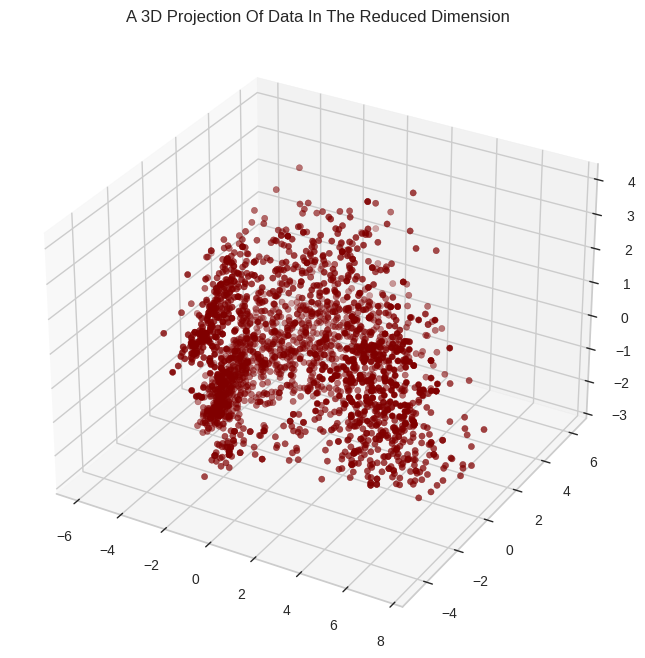

In [ ]:
# PCA로 축소된 데이터의 3차원 시각화
x = PCA_ds["col1"]
y = PCA_ds["col2"]
z = PCA_ds["col3"]

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(x, y, z, c="maroon", marker="o")

ax.set_title(
    "A 3D Projection Of Data In The Reduced Dimension"
)

plt.show()

## **5. 군집화(Clustering)**

### Steps involved in the Clustering
- 실루엣 계수와 Elbow Method를 통한 최적 군집 개수 선정
- K-means 방법을 활용한 군집화 및 평가

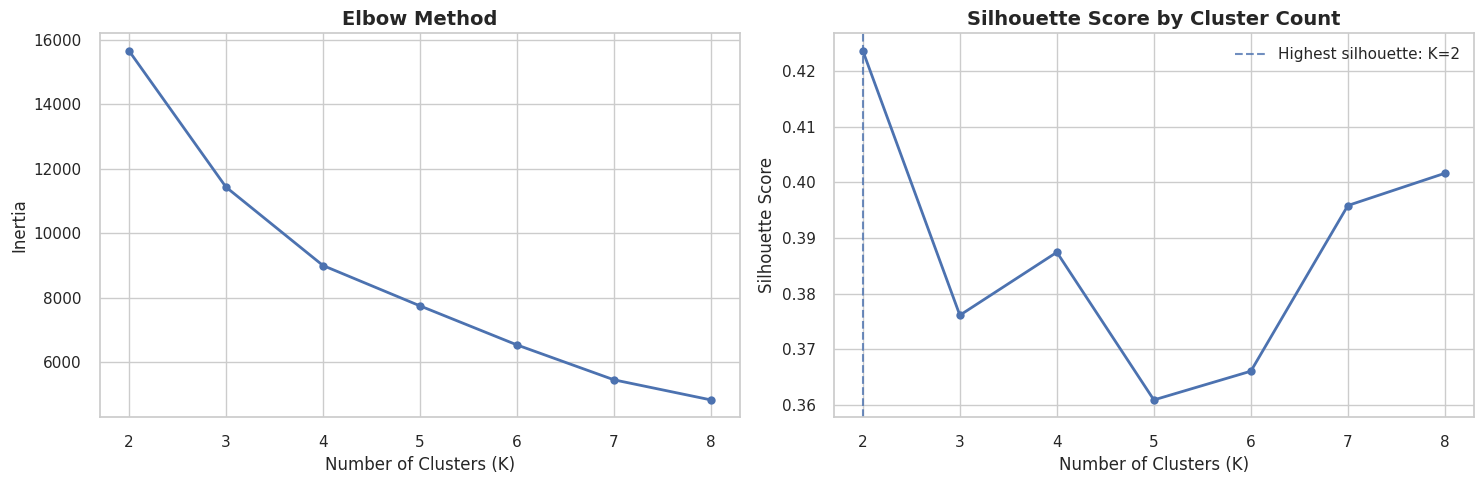

,K,Inertia,Silhouette Score
0,2,15661.3848,0.4236
6,8,4825.6758,0.4016
5,7,5449.3603,0.3958
2,4,8997.7006,0.3874
1,3,11432.1241,0.3761
4,6,6532.5042,0.3661
3,5,7744.8030,0.3609


실루엣 계수가 가장 높은 군집 수: K=2


In [ ]:
# 5-1. 최적 군집 개수 탐색

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)

# PCA 결과에서 실제 주성분 3개만 사용
X_pca = PCA_ds[["col1", "col2", "col3"]].copy()

# 군집 개수별 성능 평가
k_values = range(2, 9)
inertias = []
silhouette_scores = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20,
        max_iter=500
    )

    cluster_labels = model.fit_predict(X_pca)

    inertias.append(model.inertia_)
    silhouette_scores.append(
        silhouette_score(X_pca, cluster_labels)
    )

# Elbow Method + Silhouette Score
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(
    list(k_values), inertias,
    marker="o", linewidth=2
)
axes[0].set_title("Elbow Method", fontsize=14, weight="bold")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(list(k_values))

axes[1].plot(
    list(k_values), silhouette_scores,
    marker="o", linewidth=2
)
axes[1].set_title(
    "Silhouette Score by Cluster Count",
    fontsize=14, weight="bold"
)
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(list(k_values))

best_k = list(k_values)[np.argmax(silhouette_scores)]

axes[1].axvline(
    best_k, linestyle="--", alpha=0.8,
    label=f"Highest silhouette: K={best_k}"
)
axes[1].legend()

plt.tight_layout()
plt.show()

# 결과표
evaluation_df = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertias,
    "Silhouette Score": silhouette_scores
})

display(
    evaluation_df.sort_values(
        "Silhouette Score", ascending=False
    ).round(4)
)

print(f"실루엣 계수가 가장 높은 군집 수: K={best_k}")

#### 실루엣 계수와 Elbow Method 결과를 기반으로 k=2로 군집화 진행

### K-Means 군집화 진행

In [ ]:
# 군집 수 설정
FINAL_K = 2

kmeans = KMeans(
    n_clusters=FINAL_K,
    random_state=42,
    n_init=20,
    max_iter=500
)

labels = kmeans.fit_predict(X_pca)

# 기존 군집 결과를 통일해서 갱신
data["Clusters"] = labels

PCA_ds2 = X_pca.copy()
PCA_ds2["Clusters"] = labels

# 군집별 고객 수 및 비율
cluster_summary = data.groupby("Clusters").size().to_frame(
    "Customers"
)

cluster_summary["Percentage (%)"] = (
    cluster_summary["Customers"] / len(data) * 100
).round(2)

display(cluster_summary)

,Customers,Percentage (%)
Clusters,,
0,1361,61.53
1,851,38.47


### 군집화 결과 시각화

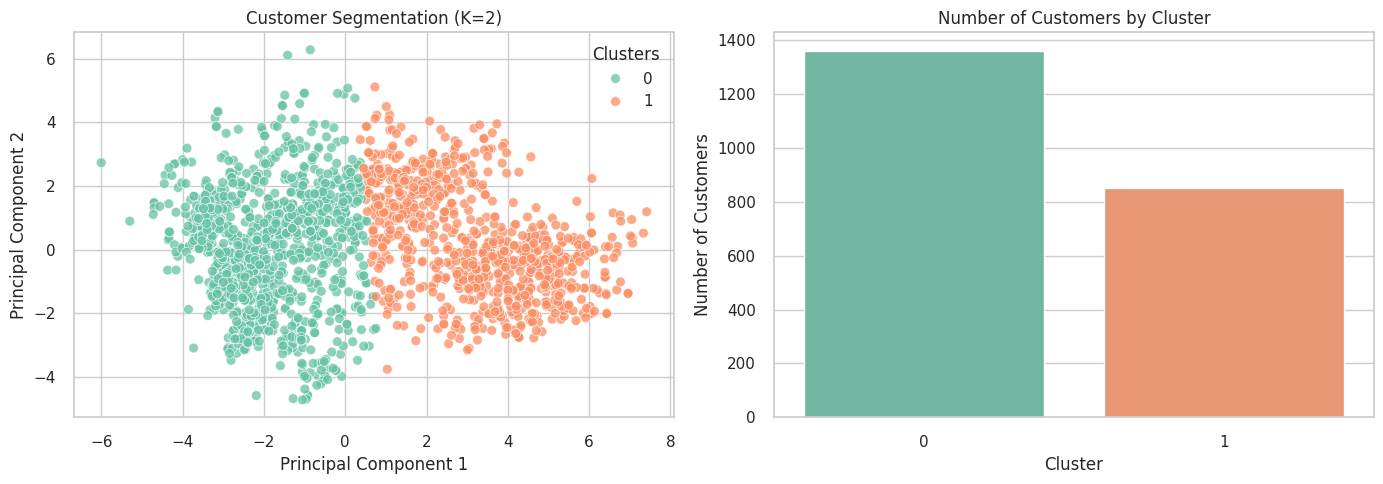

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# PCA 2차원 군집 분포
sns.scatterplot(
    data=PCA_ds2,
    x="col1",
    y="col2",
    hue="Clusters",
    palette="Set2",
    s=50,
    alpha=0.75,
    ax=axes[0]
)

axes[0].set_title("Customer Segmentation (K=2)")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")

# 군집별 고객 수
sns.countplot(
    data=data,
    x="Clusters",
    hue="Clusters",
    palette="Set2",
    legend=False,
    ax=axes[1]
)

axes[1].set_title("Number of Customers by Cluster")
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()

### 군집별 특성 확인

In [ ]:
# 군집별 고객 특성 비교
features = [
    "Age", "Income", "Spent",
    "Wines", "Fruits", "Meat",
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases",
    "NumWebVisitsMonth",
    "Children"
]

features = [col for col in features if col in data.columns]

profile = data.groupby("Clusters")[features].mean().round(2)

display(profile.T)

Clusters,0,1
Age,51.02,53.80
Income,39451.72,71961.34
Spent,206.60,1248.06
Wines,119.23,602.84
Fruits,6.99,57.26
Meat,39.90,370.35
NumWebPurchases,3.09,5.68
NumCatalogPurchases,0.96,5.41
NumStorePurchases,4.08,8.56
NumWebVisitsMonth,6.39,3.62


- 군집 0은 저소비·자녀 동거형 고객, 군집 1은 고소득·고소비 고객

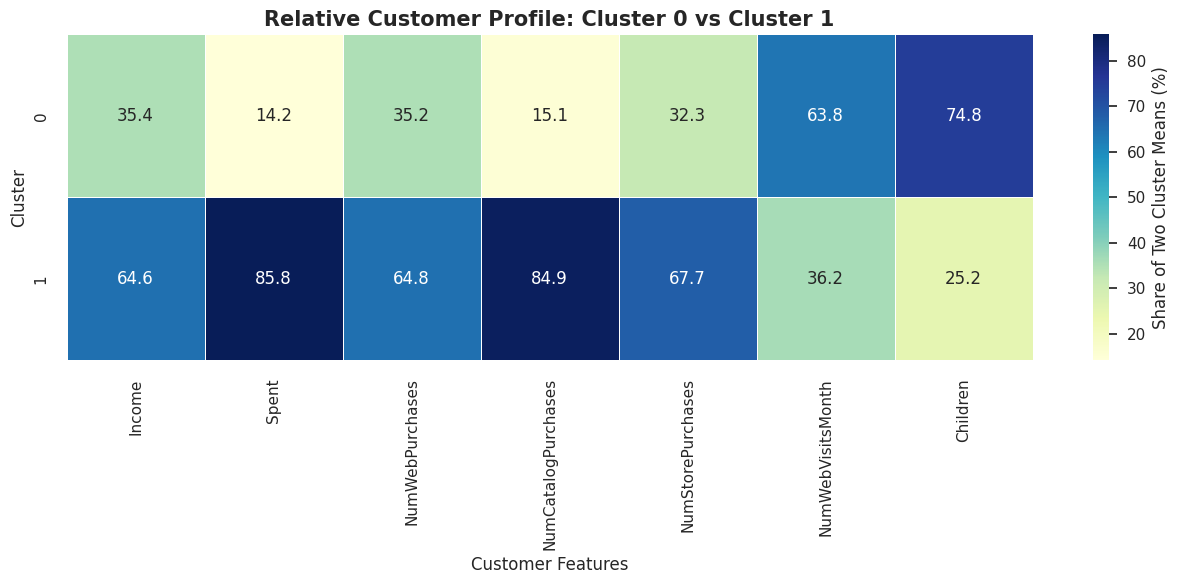

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

compare_features = [
    "Income",
    "Spent",
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases",
    "NumWebVisitsMonth",
    "Children"
]

compare_features = [
    c for c in compare_features if c in data.columns
]

profile = data.groupby("Clusters")[compare_features].mean()

# 변수마다 단위가 다르므로 군집별 평균을 변수 단위로 비교
# 각 변수에서 두 군집의 평균이 합계 100%가 되도록 표시
relative_profile = (
    profile.div(profile.sum(axis=0).replace(0, 1), axis=1) * 100
)

plt.figure(figsize=(13, 6))

sns.heatmap(
    relative_profile,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "Share of Two Cluster Means (%)"}
)

plt.title("Relative Customer Profile: Cluster 0 vs Cluster 1",
          fontsize=15, weight="bold")
plt.xlabel("Customer Features")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()

#### **Cluster 0 — 정보 탐색형·자녀 동거 고객**
- 소득 평균 비중: 35.4%
- 소비 평균 비중: 14.2%
- 웹 구매 평균 비중: 35.2%
- 월간 웹 방문 평균 비중: 63.8%
- 자녀 수 평균 비중: 74.8%

#### **Cluster 1 — 고소비·다채널 구매 고객**
- 소득 평균 비중: 64.6%
- 소비 평균 비중: 85.8%
- 웹 구매 평균 비중: 64.8%
- 카탈로그 구매 평균 비중: 84.9%
- 매장 구매 평균 비중: 67.7%

## **6. 평가**

###

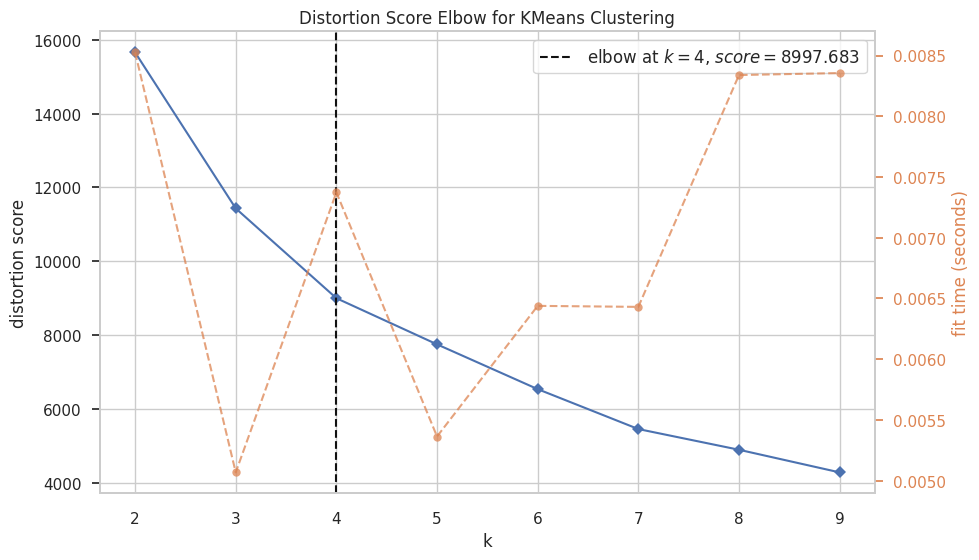

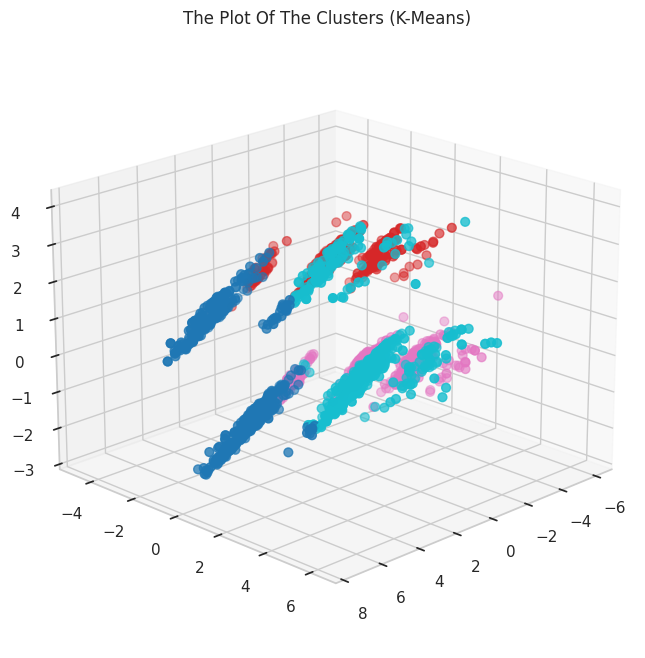

/tmp/ipykernel_741/1276033666.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  pl = sns.countplot(x=data["Clusters"], palette=pal)
/tmp/ipykernel_741/1276033666.py:26: UserWarning: The palette list has more values (10) than needed (4), which may not be intended.
  pl = sns.countplot(x=data["Clusters"], palette=pal)


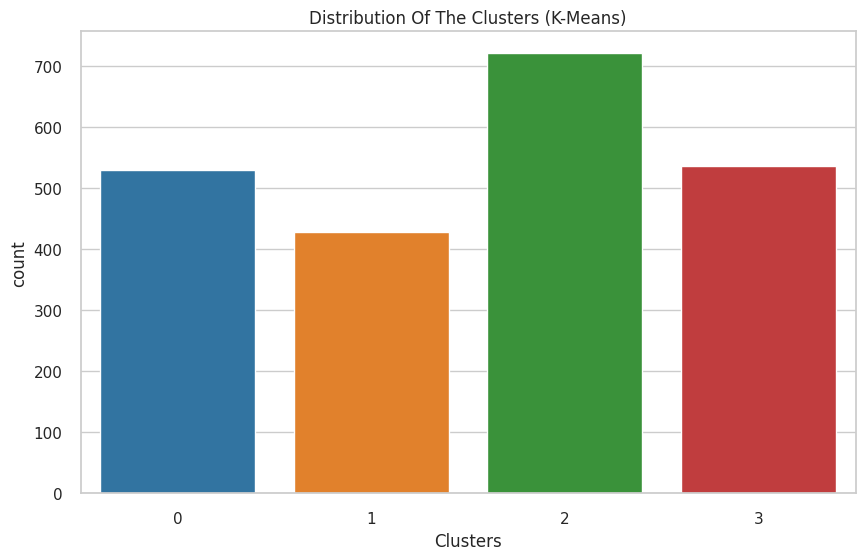

/tmp/ipykernel_741/1276033666.py:31: UserWarning: The palette list has more values (10) than needed (4), which may not be intended.
  pl = sns.scatterplot(data=data, x="Spent", y="Income", hue="Clusters", palette=pal)


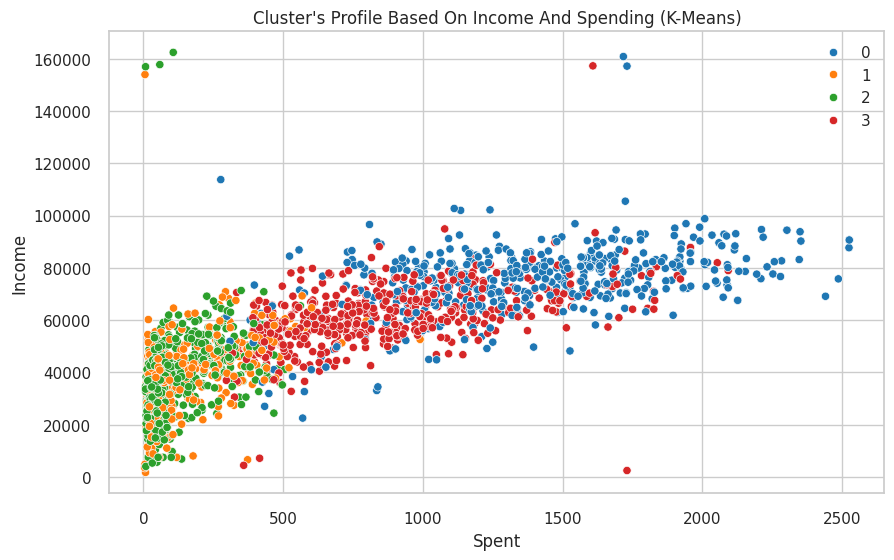

Silhouette Score for K-Means (k=4): 0.3874


In [ ]:
## Yellowbrick 라이브러리를 사용해 최적의 클러스터 개수(K)를 Elbow Method로 찾음.
visualizer = KElbowVisualizer(KMeans(random_state=42), k=(2, 10))
visualizer.fit(PCA_ds)
visualizer.show()

## Elbow 결과 또는 설정하고자 하는 군집 수 지정함. (기본값 4로 설정함)
k_chosen = 4
kmeans = KMeans(n_clusters=k_chosen, random_state=42)

## PCA 차원 축소 데이터에 K-Means 클러스터링 적용함.
yhat_kmeans = kmeans.fit_predict(PCA_ds)

## 원본 데이터와 PCA 데이터셋에 군집 결과(Clusters) 컬럼을 추가함.
PCA_ds["Clusters"] = yhat_kmeans
data["Clusters"] = yhat_kmeans

## 3차원 공간에서 K-Means 군집 결과를 시각화함.
fig = plt.figure(figsize=(10, 8))
ax = plt.subplot(111, projection='3d', elev=20, azim=45)
ax.scatter(PCA_ds["col1"], PCA_ds["col2"], PCA_ds["col3"], s=40, c=PCA_ds["Clusters"], marker='o', cmap='tab10')
ax.set_title("The Plot Of The Clusters (K-Means)")
plt.show()

## 군집별 고객 수 분포 확인 및 시각화함.
pal = sns.color_palette("tab10")
pl = sns.countplot(x=data["Clusters"], palette=pal)
pl.set_title("Distribution Of The Clusters (K-Means)")
plt.show()

## 군집별 총 지출액(Spent)과 소득(Income) 관계 시각화함.
pl = sns.scatterplot(data=data, x="Spent", y="Income", hue="Clusters", palette=pal)
pl.set_title("Cluster's Profile Based On Income And Spending (K-Means)")
plt.legend()
plt.show()

## 실루엣 점수(Silhouette Score)로 군집화 성능을 평가함.
silhouette_avg = metrics.silhouette_score(PCA_ds[["col1", "col2", "col3"]], yhat_kmeans)
print(f"Silhouette Score for K-Means (k={k_chosen}): {silhouette_avg:.4f}")

1. 최적 군집 수 선정( Distortion Score Elbow for KMeans Clustering)


* KElbowVisualizer 분석 결과, k=4 지점에서 기울기가 완만해지는 꺾임점(Elbow Point)이 명확히 관찰됨.   
* 해당 지점의 Distortion Score는 약 8997.683으로 측정되었으며, 모델의 효율성과 군집 간 구분감을 고려해 최적 군집 개수를 4개로 결정함.   

2. 3차원 군집 산점도 (The Plot Of The Clusters (K-Means))
PCA를 통해 축소된 3차원 공간(col1, col2, col3)상에서 데이터 포인트들이 4개의 군집으로 분리됨을 확인함.   

* 각 군집 간의 경계가 형성되어 K-Means 알고리즘이 공간상에서 군집화를 효과적으로 수행함을 보여줌.   

3. 군집별 데이터 수 분포 (Distribution Of The Clusters (K-Means))

* 군집별 데이터 개수를 비교한 결과, Cluster 2가 700여 개로 가장 높은 비중을 차지함.   
* Cluster 0, 1, 3 역시 400~500개 수준의 데이터 수를 유지하며 전체적으로 특정 군집에 과도하게 치우치지 않고 비교적 균등하게 분포함을 확인함.   


4. 소득과 총 소비 금액 기준 군집 프로파일 분석 (Cluster's Profile Based On Income And Spending (K-Means))

* Group 0 (블루): 평균 소득 수준(약 6만~9만 달러)을 형성하면서 1,500달러 이상의 높은 지출을 보이는 '고지출-평균소득' 그룹임.   
* Group 1 (오렌지): 소득 수준(약 2만~6만 달러) 대비 지출액(500달러 미만)이 낮은 '저소득-저지출' 가성비 중심 그룹임.   
* Group 2 (그린): 소득 수준은 2만~6만 달러 수준이나 500달러 미만의 실속형 소비를 보이는 그룹 형태임.   
* Group 3 (레드): 소득 약 5만~8만 달러 구간에서 500~1,500달러 범위의 중상위권 소비를 유지하는 '중간 소득-중상위 지출' 그룹임.